# Analisis Pendapatan Transaksi POS 2024 – 2025

**Tujuan:** menghitung total pendapatan per tahun (2024 dan 2025) dari data transaksi POS.

**Langkah kerja:**
1. Membaca file CSV
2. Memeriksa kualitas data (missing value, duplikat, format aneh)
3. Membersihkan data
4. Menghitung pendapatan dengan memperhatikan **diskon** dan **status**
5. Menyimpan hasil ke folder `output/`

**Rumus pendapatan per baris:**
`pendapatan = jumlah × harga_satuan × (1 − diskon_persen / 100)`

## 1. Import library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.0f}'.format

## 2. Membaca file
Semua kolom dibaca sebagai teks (`dtype=str`) dulu, karena ada harga berformat `13.000` dan `7500,00` yang akan salah dibaca jika dibiarkan otomatis.

In [2]:
PATH = '../data/raw/paket_a_transaksi_pos_2024_2025.csv'
df_raw = pd.read_csv(PATH, dtype=str)
print('Jumlah baris & kolom:', df_raw.shape)
df_raw.head()

Jumlah baris & kolom: (5030, 9)


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


## 3. Pemeriksaan kualitas data

In [3]:
print('--- Missing value per kolom ---')
print(df_raw.isna().sum())
print()
print('Baris duplikat persis      :', df_raw.duplicated().sum())
print('ID transaksi ganda         :', df_raw['id_transaksi'].duplicated().sum())
print()
print('--- Status ---')
print(df_raw['status'].value_counts())
print()
print('--- Diskon (%) ---')
print(df_raw['diskon_persen'].value_counts())

--- Missing value per kolom ---
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64

Baris duplikat persis      : 30
ID transaksi ganda         : 30

--- Status ---
status
SELESAI    4749
BATAL       191
RETUR        90
Name: count, dtype: int64

--- Diskon (%) ---
diskon_persen
0     3848
10     420
5      346
15     271
20     145
Name: count, dtype: int64


In [4]:
# Pola format tanggal (9 = angka)
print(df_raw['tanggal'].str.replace(r'\d', '9', regex=True).value_counts())
print()
# Harga yang formatnya bukan angka murni
harga_aneh = df_raw.loc[~df_raw['harga_satuan'].str.fullmatch(r'\d+'), 'harga_satuan']
print('Harga berformat aneh:', len(harga_aneh), '-> contoh:', harga_aneh.head(5).tolist())
print()
# Kode produk yang kotor (spasi / huruf kecil / kode XXX)
kp = df_raw['kode_produk']
print('Kode produk ada spasi   :', (kp != kp.str.strip()).sum())
print('Kode produk huruf kecil :', (kp.str.strip() != kp.str.strip().str.upper()).sum())
print('Kode produk XXX...      :', kp.str.strip().str.upper().str.startswith('XXX').sum())
print()
# Distribusi jumlah barang
jml = pd.to_numeric(df_raw['jumlah'])
print('Jumlah negatif          :', (jml < 0).sum())
print('Jumlah > 12 (mencurigakan):', (jml > 12).sum())
print(jml.value_counts().sort_index().head(20))

tanggal
9999-99-99    4839
99-99-9999     105
99/99/9999      86
Name: count, dtype: int64

Harga berformat aneh: 96 -> contoh: ['7500,00', '11000,00', '13.000', '27000,00', '13500,00']

Kode produk ada spasi   : 106
Kode produk huruf kecil : 45
Kode produk XXX...      : 56

Jumlah negatif          : 41
Jumlah > 12 (mencurigakan): 12
jumlah
-12         3
-6          2
-4          4
-3          4
-2         12
-1         16
 1       1967
 2       1218
 3        750
 4        538
 6        354
 12       150
 641        1
 661        1
 746        1
 759        1
 892        1
 1280       1
 1301       1
 1310       1
Name: count, dtype: int64


### Temuan masalah data & cara penanganannya

| # | Masalah | Penanganan |
|---|---------|-----------|
| 1 | `kode_kasir` kosong | Diisi `TIDAK_DIKETAHUI` (kolom ini tidak mempengaruhi pendapatan) |
| 2 | Baris duplikat persis | Dihapus (disisakan 1) |
| 3 | Format tanggal campuran (`2024-12-28`, `26/03/2025`, `23-12-2024`) | Diseragamkan ke format tanggal |
| 4 | Format harga campuran (`13.000`, `7500,00`) | Dibersihkan menjadi angka |
| 5 | `kode_produk` ada spasi / huruf kecil | `strip()` dan `upper()` |
| 6 | `jumlah` negatif | Dianggap salah tanda input → diambil nilai mutlaknya |
| 7 | `jumlah` ekstrem (> 12, padahal normalnya 1–12) | Dianggap salah input → **dikeluarkan** dari perhitungan dan disimpan di file tersendiri |
| 8 | Status `BATAL` dan `RETUR` | `BATAL` tidak dihitung; `RETUR` dikurangkan (lihat bagian 5) |

## 4. Pembersihan data

In [5]:
df = df_raw.copy()

# 1) Hapus duplikat persis
n_awal = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Duplikat dihapus:', n_awal - len(df))

# 2) Missing value: kode_kasir
df['kode_kasir'] = df['kode_kasir'].fillna('TIDAK_DIKETAHUI')

# 3) Rapikan teks
df['kode_produk'] = df['kode_produk'].str.strip().str.upper()
df['status'] = df['status'].str.strip().str.upper()

# 4) Tanggal: ada 3 format -> parse satu per satu
def parse_tanggal(s):
    s = s.strip()
    if s[4] == '-':                      # 2024-12-28
        return pd.to_datetime(s, format='%Y-%m-%d')
    if '/' in s:                         # 26/03/2025
        return pd.to_datetime(s, format='%d/%m/%Y')
    return pd.to_datetime(s, format='%d-%m-%Y')   # 23-12-2024

df['tanggal'] = df['tanggal'].apply(parse_tanggal)
df['tahun'] = df['tanggal'].dt.year

# 5) Harga: '13.000' -> 13000 ; '7500,00' -> 7500
df['harga_satuan'] = (df['harga_satuan']
                      .str.replace(',00', '', regex=False)
                      .str.replace('.', '', regex=False)
                      .astype(float))

# 6) Angka lain
df['diskon_persen'] = df['diskon_persen'].astype(float)
df['jumlah'] = pd.to_numeric(df['jumlah']).abs()      # negatif -> positif

print('Sisa missing value:'); print(df.isna().sum()[lambda x: x > 0])
print('Rentang tanggal:', df['tanggal'].min().date(), 's/d', df['tanggal'].max().date())
df.dtypes

Duplikat dihapus: 30


Sisa missing value:
Series([], dtype: int64)
Rentang tanggal: 2024-01-01 s/d 2025-12-31


id_transaksi                str
tanggal          datetime64[us]
kode_gerai                  str
kode_kasir                  str
kode_produk                 str
jumlah                    int64
harga_satuan            float64
diskon_persen           float64
status                      str
tahun                     int32
dtype: object

In [6]:
# 7) Tandai jumlah ekstrem (> 12) dan pisahkan
BATAS_JUMLAH = 12
df['outlier_jumlah'] = df['jumlah'] > BATAS_JUMLAH
outlier = df[df['outlier_jumlah']]
print('Baris dengan jumlah ekstrem:', len(outlier))
outlier[['id_transaksi','tanggal','kode_produk','jumlah','harga_satuan','diskon_persen','status']]

Baris dengan jumlah ekstrem: 12


,id_transaksi,tanggal,kode_produk,jumlah,harga_satuan,diskon_persen,status
87,TRX0243886,2025-12-27,PRW1306,2375,"14,500",0,SELESAI
244,TRX0243257,2024-11-24,MKN1102,1456,"32,500",20,SELESAI
466,TRX0243696,2024-02-27,SGR1201,892,"54,000",0,SELESAI
659,TRX0242847,2025-02-24,RMT1404,661,"13,000",5,BATAL
925,TRX0240632,2024-09-08,RMT1403,1280,"6,500",0,SELESAI
993,TRX0241002,2024-03-18,MKN1101,2093,"48,000",10,SELESAI
1034,TRX0241068,2025-09-17,SGR1202,759,"13,500",5,SELESAI
1320,TRX0240401,2025-02-02,MIN1009,641,"11,500",0,SELESAI
2409,TRX0241473,2024-12-08,PRW1308,1310,"11,000",0,SELESAI
3209,TRX0242632,2025-11-19,SGR1204,746,"41,500",0,SELESAI


## 5. Menghitung pendapatan (diskon & status)

In [7]:
# Pendapatan setelah diskon
df['pendapatan'] = df['jumlah'] * df['harga_satuan'] * (1 - df['diskon_persen'] / 100)

# Baris valid = bukan outlier
valid = df[~df['outlier_jumlah']]

# Ringkasan per status & tahun (bantu cek)
ringkas_status = valid.pivot_table(index='tahun', columns='status', values='pendapatan',
                                   aggfunc='sum', fill_value=0)
ringkas_status

status,BATAL,RETUR,SELESAI
tahun,,,
2024,"4,899,850","2,432,575","128,048,525"
2025,"3,846,150","2,933,625","136,467,375"


In [8]:
# Pendapatan kotor  = hanya status SELESAI
# Retur             = status RETUR (dikurangkan)
# BATAL             = tidak dihitung
hasil = pd.DataFrame({
    'pendapatan_selesai': ringkas_status['SELESAI'],
    'retur':              ringkas_status['RETUR'],
    'batal_diabaikan':    ringkas_status['BATAL'],
})
hasil['pendapatan_bersih'] = hasil['pendapatan_selesai'] - hasil['retur']
hasil['jumlah_transaksi_selesai'] = valid[valid['status'] == 'SELESAI'].groupby('tahun').size()
hasil

,pendapatan_selesai,retur,batal_diabaikan,pendapatan_bersih,jumlah_transaksi_selesai
tahun,,,,,
2024,"128,048,525","2,432,575","4,899,850","125,615,950",2343
2025,"136,467,375","2,933,625","3,846,150","133,533,750",2365


## 6. Visualisasi

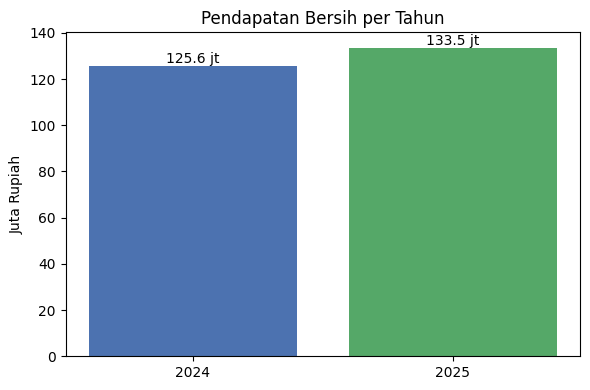

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
x = hasil.index.astype(str)
ax.bar(x, hasil['pendapatan_bersih'] / 1e6, color=['#4C72B0', '#55A868'])
for i, v in enumerate(hasil['pendapatan_bersih'] / 1e6):
    ax.text(i, v, f'{v:,.1f} jt', ha='center', va='bottom')
ax.set_title('Pendapatan Bersih per Tahun')
ax.set_ylabel('Juta Rupiah')
plt.tight_layout()
plt.savefig('../output/pendapatan_per_tahun.png', dpi=150)
plt.show()

## 7. Menyimpan hasil

In [10]:
hasil.to_csv('../output/pendapatan_per_tahun.csv')
df.to_csv('../data/processed/transaksi_bersih.csv', index=False)
outlier.to_csv('../output/baris_outlier_dikeluarkan.csv', index=False)
print('Tersimpan: output/pendapatan_per_tahun.csv, output/pendapatan_per_tahun.png,')
print('           output/baris_outlier_dikeluarkan.csv, data/processed/transaksi_bersih.csv')

Tersimpan: output/pendapatan_per_tahun.csv, output/pendapatan_per_tahun.png,
           output/baris_outlier_dikeluarkan.csv, data/processed/transaksi_bersih.csv


## 8. Kesimpulan
Lihat tabel `hasil` di atas. Angka **pendapatan_bersih** adalah angka utama (SELESAI dikurangi RETUR, sudah dipotong diskon, BATAL tidak dihitung, outlier jumlah dikeluarkan).

**Asumsi yang dipakai (silakan disesuaikan dengan aturan bisnis sebenarnya):**
- RETUR dikurangkan dari pendapatan, dengan nilai yang sama dengan rumus penjualan.
- `jumlah` negatif dianggap salah tanda, bukan retur.
- `jumlah` > 12 dianggap salah input dan dikeluarkan.
- Kode produk `XXX…` tetap dihitung karena harga dan jumlahnya valid (hanya kode produknya tidak dikenal).